In [4]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"eeyaal29","key":"882ca28a7a268eeb5f69db96bdbdda36"}'}

In [5]:
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [7]:
!pip install kaggle
!kaggle datasets download -d joosthazelzet/lego-brick-images --unzip -p ./dataset

Dataset URL: https://www.kaggle.com/datasets/joosthazelzet/lego-brick-images
License(s): GPL-2.0
100% 1.00G/1.00G [00:12<00:00, 88.3MB/s]



In [13]:
# Cellule — Collecter uniquement les vraies images
dataset_images = []
for root, dirs, files in os.walk('./dataset'):
    # Exclure le dossier Collada models (bump maps)
    if 'Collada models' in root:
        continue
    for f in files:
        if f.endswith(('.png', '.jpg', '.jpeg')):
            dataset_images.append(os.path.join(root, f))

print(f"Total images valides : {len(dataset_images)}")

Total images valides : 46379


In [16]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
import torchvision.utils as vutils
from torch.utils.data import DataLoader, Dataset
from PIL import Image
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt

# --------------------
# Hyperparameters
# --------------------
IMAGE_SIZE = 64
CHANNELS = 1
BATCH_SIZE = 128
Z_DIM = 100
EPOCHS = 5
LEARNING_RATE = 0.0002
BETA1 = 0.5
BETA2 = 0.999

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
NOISE_PARAM = 0.1

# --------------------
# Transforms
# --------------------
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# --------------------
# Dataset & DataLoader
# --------------------
class ImageDataset(Dataset):
    def __init__(self, image_paths, transform=None):
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image

# Instanciation
dataset = ImageDataset(image_paths=dataset_images, transform=transform)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

print(f"Nombre de batches : {len(dataloader)}")

Nombre de batches : 363
Nombre d'images : 46379


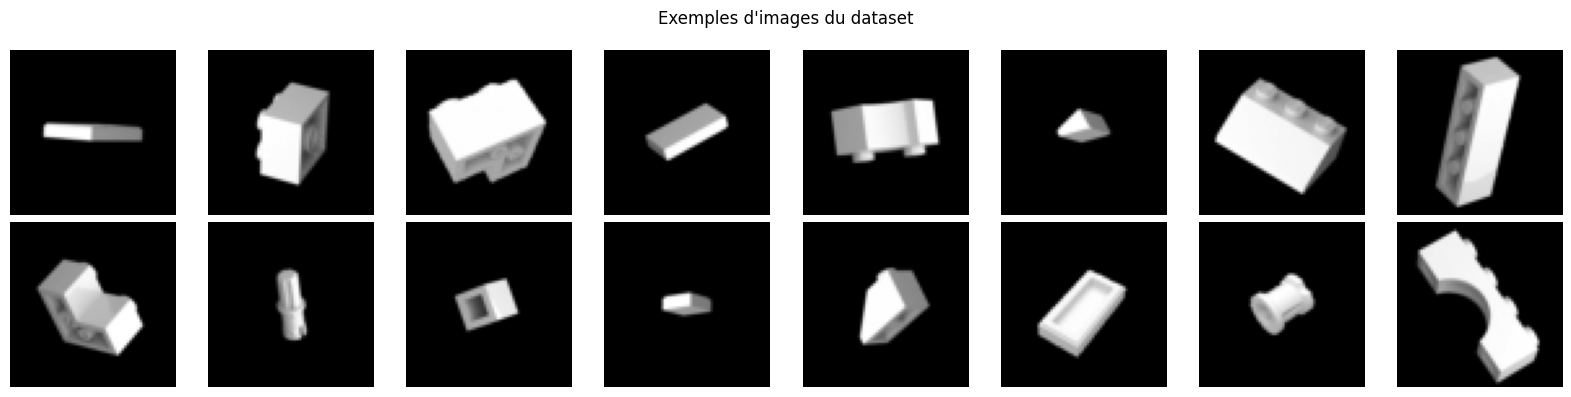

In [19]:
def plot_sample_images(loader):
    batch = next(iter(loader))  # shape: (BATCH_SIZE, 1, 64, 64)

    fig, axes = plt.subplots(2, 8, figsize=(16, 4))
    axes = axes.flatten()

    for i in range(16):
        img = batch[i].squeeze().numpy()  # (64, 64)
        # Dénormalise de [-1,1] vers [0,1] pour l'affichage
        img = (img * 0.5) + 0.5
        axes[i].imshow(img, cmap='gray')
        axes[i].axis('off')

    plt.suptitle("Exemples d'images du dataset")
    plt.tight_layout()
    plt.show()

plot_sample_images(dataloader)

In [22]:
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        self.model = nn.Sequential(
            # Input shape: (1, 64, 64)
            nn.Conv2d(CHANNELS, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),

            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),

            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),

            nn.Conv2d(256, 512, 4, 2, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),

            # Output: (1, 1, 1) -> scalar
            nn.Conv2d(512, 1, 4, 1, 0, bias=False),
            nn.Sigmoid(),
            nn.Flatten(start_dim=1)  # shape: (batch_size, 1)
        )

    def forward(self, x):
        return self.model(x)

In [23]:
class Generator(nn.Module):
    def __init__(self):
        super(Generator, self).__init__()
        self.model = nn.Sequential(
            # Input: (Z_DIM, 1, 1) → (512, 4, 4)
            nn.ConvTranspose2d(Z_DIM, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            # (512, 4, 4) → (256, 8, 8)
            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            # (256, 8, 8) → (128, 16, 16)
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            # (128, 16, 16) → (64, 32, 32)
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),

            # (64, 32, 32) → (CHANNELS, 64, 64)
            nn.ConvTranspose2d(64, CHANNELS, 4, 2, 1, bias=False),
            nn.Tanh()  # Output dans [-1,1]
        )

    def forward(self, x):
        return self.model(x)

# Instanciation
critic = Discriminator().to(DEVICE)
generator = Generator().to(DEVICE)

print(critic)
print(generator)

Discriminator(
  (model): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Dropout(p=0.3, inplace=False)
    (3): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): LeakyReLU(negative_slope=0.2, inplace=True)
    (6): Dropout(p=0.3, inplace=False)
    (7): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (8): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): LeakyReLU(negative_slope=0.2, inplace=True)
    (10): Dropout(p=0.3, inplace=False)
    (11): Conv2d(256, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (12): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): LeakyReLU(negative_slope=0.2, inplace=True)
    (14

In [24]:
criterion = nn.BCELoss()  # Binary Cross Entropy

d_optimizer = optim.Adam(critic.parameters(), lr=LEARNING_RATE, betas=(BETA1, BETA2))
g_optimizer = optim.Adam(generator.parameters(), lr=LEARNING_RATE, betas=(BETA1, BETA2))

In [25]:
g_loss_values = []
d_loss_values = []
g_acc_values  = []
d_acc_values  = []

for epoch in range(EPOCHS):
    g_loss_batch = []
    d_loss_batch = []
    g_acc_batch  = []
    d_acc_batch  = []

    progress_bar = tqdm(enumerate(dataloader), total=len(dataloader),
                        desc=f"Epoch {epoch+1}/{EPOCHS}")

    for i, real_images in progress_bar:
        real_images = real_images.to(DEVICE)
        batch_size  = real_images.size(0)

        # -------------------------------------------------------
        # 1) Train Discriminator
        # -------------------------------------------------------
        d_optimizer.zero_grad()

        # Labels réels proches de 1, avec bruit
        real_labels      = torch.ones(batch_size, 1, device=DEVICE)
        real_noisy_labels = real_labels - NOISE_PARAM * torch.rand_like(real_labels)

        # Labels faux proches de 0, avec bruit
        fake_labels      = torch.zeros(batch_size, 1, device=DEVICE)
        fake_noisy_labels = fake_labels + NOISE_PARAM * torch.rand_like(fake_labels)

        # Images réelles
        real_preds = critic(real_images)
        real_loss  = criterion(real_preds, real_noisy_labels)

        # Images générées
        z          = torch.randn(batch_size, Z_DIM, 1, 1, device=DEVICE)
        fake_images = generator(z)
        fake_preds  = critic(fake_images.detach())
        fake_loss   = criterion(fake_preds, fake_noisy_labels)

        d_loss = (real_loss + fake_loss) / 2
        d_loss.backward()
        d_optimizer.step()

        # Accuracy du discriminateur
        d_real_acc = (real_preds.round() == real_labels).float().mean().item()
        d_fake_acc = (fake_preds.round() == fake_labels).float().mean().item()
        d_acc      = (d_real_acc + d_fake_acc) / 2

        # -------------------------------------------------------
        # 2) Train Generator
        # -------------------------------------------------------
        g_optimizer.zero_grad()

        fake_preds = critic(fake_images)  # pas de detach ici
        g_loss     = criterion(fake_preds, real_labels)  # G veut que D dise "réel"
        g_loss.backward()
        g_optimizer.step()

        g_acc = (fake_preds.round() == real_labels).float().mean().item()

        # Track métriques
        d_loss_batch.append(d_loss.item())
        g_loss_batch.append(g_loss.item())
        d_acc_batch.append(d_acc)
        g_acc_batch.append(g_acc)

        progress_bar.set_postfix(D_Loss=d_loss.item(), G_Loss=g_loss.item())

    # Fin d'epoch — moyennes
    d_loss_values.append(np.mean(d_loss_batch))
    g_loss_values.append(np.mean(g_loss_batch))
    d_acc_values.append(np.mean(d_acc_batch))
    g_acc_values.append(np.mean(g_acc_batch))

    # Sauvegarde images toutes les 10 epochs
    if (epoch + 1) % 10 == 0:
        with torch.no_grad():
            z_sample    = torch.randn(16, Z_DIM, 1, 1, device=DEVICE)
            fake_sample = generator(z_sample).cpu()
        vutils.save_image(fake_sample, f"fake_sample_epoch_{epoch+1:03d}.png", normalize=True)
        print(f"Images sauvegardées : fake_sample_epoch_{epoch+1:03d}.png")

Epoch 5/5: 100%|██████████| 363/363 [03:32<00:00,  1.71it/s, D_Loss=0.581, G_Loss=0.64]


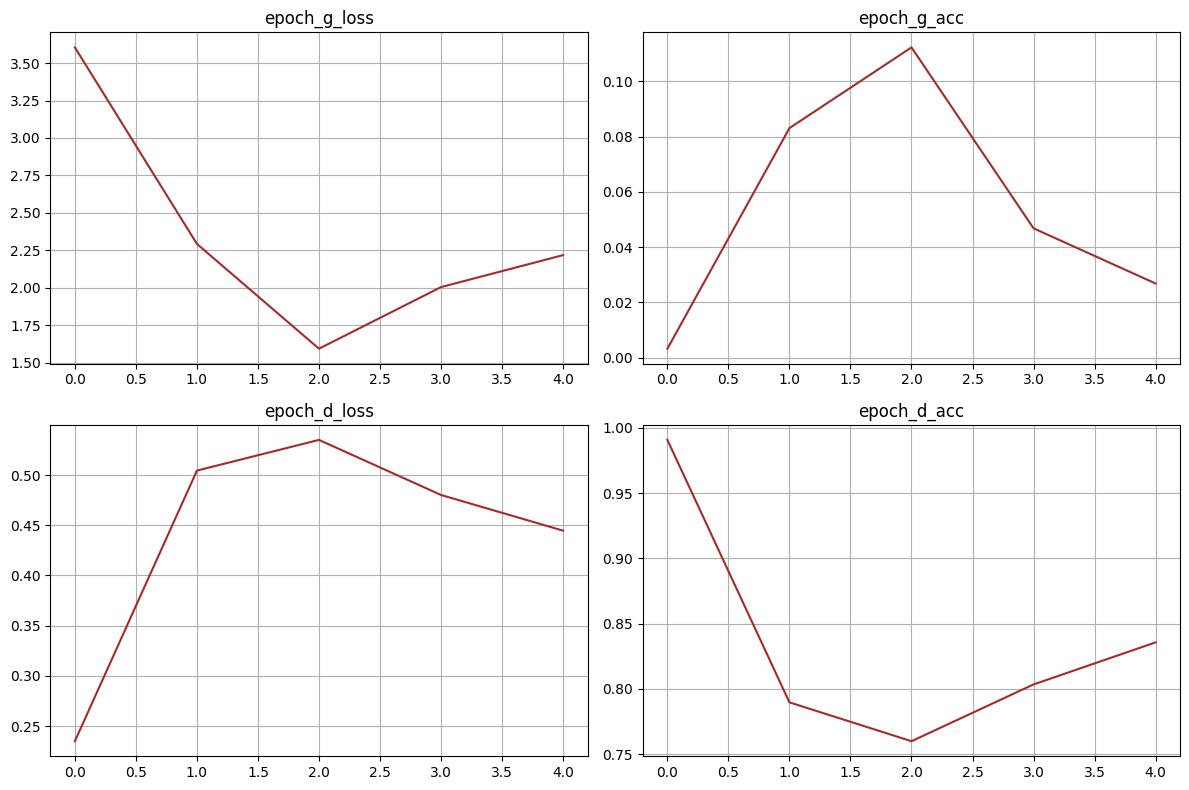

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

titles = ['epoch_g_loss', 'epoch_g_acc', 'epoch_d_loss', 'epoch_d_acc']
data   = [g_loss_values, g_acc_values, d_loss_values, d_acc_values]

for ax, title, values in zip(axes, titles, data):
    ax.plot(values, color='brown')
    ax.set_title(title)
    ax.grid(True)

plt.tight_layout()
plt.show()

### What do you observe ? What's wrong ?

epoch_d_loss ≈ 0.45-0.53 → le discriminateur est en train d'apprendre.

epoch_d_acc ≈ 75-99% → il est trop bon trop vite (epoch 1 = 99% )

epoch_g_loss reste élevée (1.5-3.5) → le générateur a du mal à tromper le discriminateur

epoch_g_acc ≈ 0-11% → le générateur trompe très rarement le discriminateur

Ce qui ne va pas :

Le discriminateur domine largement le générateur dès le début → déséquilibre

Il faudrait tester avec plus d'epoch je pense

### If the discriminator loss is near zero but the generator loss is large, what does that imply?

Le discriminateur est trop puissant, il classe parfaitement réel/faux. Le gradient qui remonte au générateur devient quasi nul, il n'apprend plus. C'est le problème de vanishing gradient dans les GANs.

Mode collapse :

Le générateur génère toujours la même image ou pas assez variées peu importe le bruit z en entrée. On peut voir le résultat plus bas, toutes les formes sont des blobs ovales similaires, pas encore dess vraies briques distinctes.

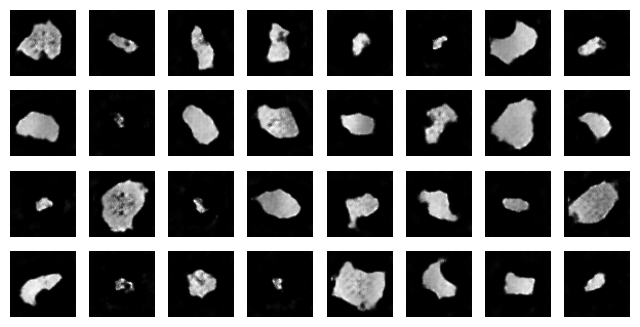

In [28]:
grid_width, grid_height = (8, 4)

z_sample = torch.randn(grid_width * grid_height, Z_DIM, 1, 1, device=DEVICE)
gen_imgs  = generator(z_sample).cpu().detach()

fig = plt.figure(figsize=(grid_width, grid_height))
for i in range(grid_width * grid_height):
    ax = fig.add_subplot(grid_height, grid_width, i + 1)
    ax.axis("off")
    # Chaque image : (1, 64, 64)
    ax.imshow(gen_imgs[i, 0, :, :], cmap="gray")

plt.show()